## Monitoría SECOP 2 - Beca Avanza

### Redes neuronales para clasificación

- Redes densas
- Redes para clasificación
- Procesamiento de datos continuos (Normalizer) y categóricos (Lookup)
- Uso de Datasets para trabajar con datos grandes
- Funciones de activación y pérdida

Empecemos importando numpy, pandas, keras, tensorflow

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

Carguemos el archivo prorrogas.csv usando pandas.

In [2]:
df = pd.read_csv('../data/processed/prorrogas.csv')

Exploremos las primeras filas del dataframe.

In [3]:
df.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,target
0,5,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.862131,222.0,1.0,0.0,0
1,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.236380,72.0,2.0,0.0,0
2,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,Si,Inversión,Distribuido,No,80,7.681241,151.0,3.0,0.0,0
3,4,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.534504,125.0,2.0,0.0,0
4,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.146433,67.0,1.0,0.0,0


Descripción de las variables:

- mes_de_firma: mes en que se firmó el contrato (1 a 12)
- modalidad_de_contratacion: modalidad de contratación
- tipo_de_contrato: tipo de contrato
- justificacion_modalidad_de: causal invocada
- nombre_entidad: entidad contratante
- tipodocproveedor: tipo de documento del contratista
- es_pyme: si el contratista es pyme
- destino_gasto: funcionamiento o inversión
- origen_de_los_recursos: origen de los recursos
- el_contrato_puede_ser_prorrogado: si el contrato puede ser prorrogado
- segmento_unspsc: segmento del bien o servicio (dos primeros dígitos del código UNSPSC)
- log_precio_base: logaritmo en base 10 del precio base del proceso
- duracion_planeada: días entre el inicio y el fin pactados
- dias_firma_a_inicio: días entre la firma y el inicio
- respuestas_al_procedimiento: ofertas recibidas
- target: 1 si el contrato tuvo prórroga, 0 si no

Exploremos el tamaño del df

In [4]:
df.shape

(52747, 16)

Identificamos NAs en los datos

In [5]:
df.isna().sum()

mes_de_firma                          0
modalidad_de_contratacion             0
tipo_de_contrato                      0
justificacion_modalidad_de            0
nombre_entidad                        0
tipodocproveedor                      0
es_pyme                               0
destino_gasto                         0
origen_de_los_recursos                0
el_contrato_puede_ser_prorrogado      0
segmento_unspsc                       0
log_precio_base                     137
duracion_planeada                    78
dias_firma_a_inicio                  78
respuestas_al_procedimiento         112
target                                0
dtype: int64

In [6]:
df.dropna(inplace=True)

In [7]:
df.shape

(52532, 16)

Definimos listas para las variables categóricas enteras, categóricas string y numéricas.

In [8]:
cat_int_feats = ['mes_de_firma']

In [9]:
cat_str_feats = ['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de',
                 'nombre_entidad', 'tipodocproveedor', 'es_pyme', 'destino_gasto',
                 'origen_de_los_recursos', 'el_contrato_puede_ser_prorrogado', 'segmento_unspsc']

In [10]:
num_feats = ['log_precio_base', 'duracion_planeada', 'dias_firma_a_inicio', 'respuestas_al_procedimiento']

Agregamos las listas de categorías

In [11]:
feats_ordered = cat_int_feats+cat_str_feats+num_feats

Reordenamos el dataframe de acuerdo con el tipo de variable

In [12]:
df = df[feats_ordered+['target']]

In [13]:
df.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,target
0,5,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.862131,222.0,1.0,0.0,0
1,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.236380,72.0,2.0,0.0,0
2,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,Si,Inversión,Distribuido,No,80,7.681241,151.0,3.0,0.0,0
3,4,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.534504,125.0,2.0,0.0,0
4,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.146433,67.0,1.0,0.0,0


Separamos los datos en entrenamiento, validación y prueba

In [14]:
train = df.sample(frac=0.8, random_state=100)
train.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,target
10092,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.548134,151.0,0.0,0.0,0
51032,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA PARA LA REINCORPORACIÓN Y LA NORMALIZA...,Cédula de Ciudadanía,No,Funcionamiento,Distribuido,No,80,8.836920,346.0,7.0,0.0,0
11287,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.352183,68.0,2.0,0.0,0
30288,5,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,Si,80,7.678946,216.0,6.0,0.0,0
45119,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,UNP,Cédula de Ciudadanía,No,Funcionamiento,Distribuido,No,80,7.054460,54.0,6.0,0.0,0


In [15]:
train.shape

(42026, 16)

In [16]:
test = df.drop(train.index)
test.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,target
9,12,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,6.835534,25.0,1.0,0.0,0
27,1,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.636787,253.0,2.0,0.0,1
28,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.405005,88.0,1.0,0.0,0
40,2,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.635627,123.0,1.0,0.0,0
44,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.236380,77.0,4.0,0.0,0


In [17]:
val = train.sample(frac=0.2, random_state=100)

In [18]:
val.shape

(8405, 16)

In [19]:
train = train.drop(val.index)

In [20]:
print(train.shape)
print(val.shape)
print(test.shape)

(33621, 16)
(8405, 16)
(10506, 16)


Calculamos estadísticas de cada variable numérica

In [21]:
train.describe()

,mes_de_firma,log_precio_base,duracion_planeada,dias_firma_a_inicio,respuestas_al_procedimiento,target
count,33621.000000,33621.000000,33621.000000,33621.000000,33621.000000,33621.000000
mean,4.340799,7.602393,187.359478,2.655721,0.054728,0.121769
std,3.570248,0.398435,95.030233,4.284068,0.894748,0.327024
min,1.000000,5.780206,0.000000,-3.000000,0.000000,0.000000
25%,1.000000,7.407247,121.000000,0.000000,0.000000,0.000000
50%,3.000000,7.572402,165.000000,2.000000,0.000000,0.000000
75%,8.000000,7.737193,248.000000,4.000000,0.000000,0.000000
max,12.000000,12.414877,1095.000000,202.000000,47.000000,1.000000


Función para convertir de dataframe (pandas) a dataset (tensorflow), separando características y etiquetas

In [22]:
def dataframe_to_dataset(dataframe):
    dataframe = dataframe.copy()
    labels = dataframe.pop("target")
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe))
    return ds

In [23]:
train_ds = dataframe_to_dataset(train)
val_ds = dataframe_to_dataset(val)
test_ds = dataframe_to_dataset(test)

In [24]:
type(train_ds)

tensorflow.python.data.ops.shuffle_op._ShuffleDataset

Ejemplo de cómo queda el tf.dataset

In [25]:
for x, y in train_ds.take(1):
    print("Input:", x)
    print("Target:", y)

Input: {'mes_de_firma': <tf.Tensor: shape=(), dtype=int64, numpy=8>, 'modalidad_de_contratacion': <tf.Tensor: shape=(), dtype=string, numpy=b'Contrataci\xc3\xb3n directa'>, 'tipo_de_contrato': <tf.Tensor: shape=(), dtype=string, numpy=b'Prestaci\xc3\xb3n de servicios'>, 'justificacion_modalidad_de': <tf.Tensor: shape=(), dtype=string, numpy=b'Servicios profesionales y apoyo a la gesti\xc3\xb3n'>, 'nombre_entidad': <tf.Tensor: shape=(), dtype=string, numpy=b'AGENCIA NACIONAL DE TIERRAS - ANT'>, 'tipodocproveedor': <tf.Tensor: shape=(), dtype=string, numpy=b'C\xc3\xa9dula de Ciudadan\xc3\xada'>, 'es_pyme': <tf.Tensor: shape=(), dtype=string, numpy=b'No'>, 'destino_gasto': <tf.Tensor: shape=(), dtype=string, numpy=b'Inversi\xc3\xb3n'>, 'origen_de_los_recursos': <tf.Tensor: shape=(), dtype=string, numpy=b'Distribuido'>, 'el_contrato_puede_ser_prorrogado': <tf.Tensor: shape=(), dtype=string, numpy=b'No'>, 'segmento_unspsc': <tf.Tensor: shape=(), dtype=string, numpy=b'80'>, 'log_precio_base'

Agrupamos los datos de entrenamiento, validación y prueba en lotes

In [26]:
batch_size = 32
train_ds = train_ds.batch(batch_size)
test_ds = test_ds.batch(batch_size)
val_ds = val_ds.batch(batch_size)

Función para codificar variables numéricas (Keras docs)

In [27]:
def encode_numerical_feature(feature, name, dataset):
    # Crea capa de normalización para este feature
    normalizer = keras.layers.Normalization()

    # Prepara el dataset para considerar únicamente la feature de interés (name)
    feature_ds = dataset.map(lambda x, y: x[name]) # selecciona variable
    feature_ds = feature_ds.map(lambda x: tf.expand_dims(x, -1)) # deja el tensor de una dimensión

    # Aprende las estadísticas de los datos (media, varianza)
    normalizer.adapt(feature_ds)

    # Aplica la normalización a la variable
    encoded_feature = normalizer(feature)
    return encoded_feature

Función para codificar variables categóricas (Keras docs)

In [28]:
def encode_categorical_feature(feature, name, dataset, is_string):
    lookup_class = keras.layers.StringLookup if is_string else keras.layers.IntegerLookup
    # Crea una capa Lookup para retornar variables 0/1 (dummies)
    # lookup: busca el valor correspondiente de la variable categórica
    lookup = lookup_class(output_mode="binary")

    # Prepara el dataset para considerar únicamente la feature de interés (name)
    feature_ds = dataset.map(lambda x, y: x[name]) # selecciona variable
    feature_ds = feature_ds.map(lambda x: tf.expand_dims(x, -1)) # deja el tensor de una dimensión

    # Aprende el conjunto de posibles valores que toma la variable categórica y asigna enteros
    lookup.adapt(feature_ds)

    # Aplica la conversión de categorías a enteros
    encoded_feature = lookup(feature)
    return encoded_feature

Creamos una lista de inputs para el modelo, de acuerdo con cada tipo de variable

In [29]:
inputs = []
for i in cat_int_feats:
  inputs.append(keras.Input(shape=(1,), name=i, dtype="int64"))

In [30]:
for i in cat_str_feats:
  inputs.append(keras.Input(shape=(1,), name=i, dtype="string"))

In [31]:
for i in num_feats:
  inputs.append(keras.Input(shape=(1,), name=i))

In [32]:
for i in inputs:
   print(i)

<KerasTensor shape=(None, 1), dtype=int64, sparse=False, ragged=False, name=mes_de_firma>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=modalidad_de_contratacion>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=tipo_de_contrato>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=justificacion_modalidad_de>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=nombre_entidad>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=tipodocproveedor>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=es_pyme>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=destino_gasto>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=origen_de_los_recursos>
<KerasTensor shape=(None, 1), dtype=string, sparse=False, ragged=False, name=el_contrato_puede_ser_prorrogado>
<KerasTensor shape=(None, 1)

Creamos una lista de variables codificadas/normalizadas de acuerdo con su tipo, empleando las funciones de codificación/normalización

In [33]:
feats_encoded=[]

In [34]:
for i,feat in enumerate(cat_int_feats):
  feats_encoded.append(
      encode_categorical_feature(inputs[i], feat, train_ds, False)
  )

In [35]:
len_feats = len(feats_encoded)
len_feats

1

In [36]:
for i,feat in enumerate(cat_str_feats):
  feats_encoded.append(
      encode_categorical_feature(inputs[len_feats+i], feat, train_ds, True)
  )

In [37]:
len_feats = len(feats_encoded)
len_feats

11

In [38]:
for i,feat in enumerate(num_feats):
  feats_encoded.append(
      encode_numerical_feature(inputs[len_feats+i], feat, train_ds)
  )

In [39]:
for i in feats_encoded:
  print(i)

<KerasTensor shape=(None, 13), dtype=float32, sparse=False, ragged=False, name=keras_tensor>
<KerasTensor shape=(None, 11), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1>
<KerasTensor shape=(None, 15), dtype=float32, sparse=False, ragged=False, name=keras_tensor_2>
<KerasTensor shape=(None, 23), dtype=float32, sparse=False, ragged=False, name=keras_tensor_3>
<KerasTensor shape=(None, 4), dtype=float32, sparse=False, ragged=False, name=keras_tensor_4>
<KerasTensor shape=(None, 7), dtype=float32, sparse=False, ragged=False, name=keras_tensor_5>
<KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_6>
<KerasTensor shape=(None, 4), dtype=float32, sparse=False, ragged=False, name=keras_tensor_7>
<KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_8>
<KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_9>
<KerasTensor shape=(None, 40), dtype=float32, sparse=False

Creamos una capa concatenando todas las variables codificadas

In [40]:
all_feats = keras.layers.concatenate(feats_encoded)

In [41]:
type(all_feats)

keras.src.backend.common.keras_tensor.KerasTensor

Agregamos una capa densa con 32 neuronas y función de activación relu

In [42]:
model_layers = keras.layers.Dense(32, activation='relu')(all_feats)

Agregamos la capa de salida con 1 neurona (probabilidad de que el contrato tenga prórroga) y función de activación sigmoide

In [43]:
model_layers = keras.layers.Dense(1, activation='sigmoid')(model_layers)

Creamos el modelo con las capas ya creadas y las variables de entrada

In [44]:
model = keras.Model(inputs, model_layers)

Compilamos el modelo, definiendo optimizador, función de pérdida y métricas adicionales a capturar

In [45]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', 'recall'])

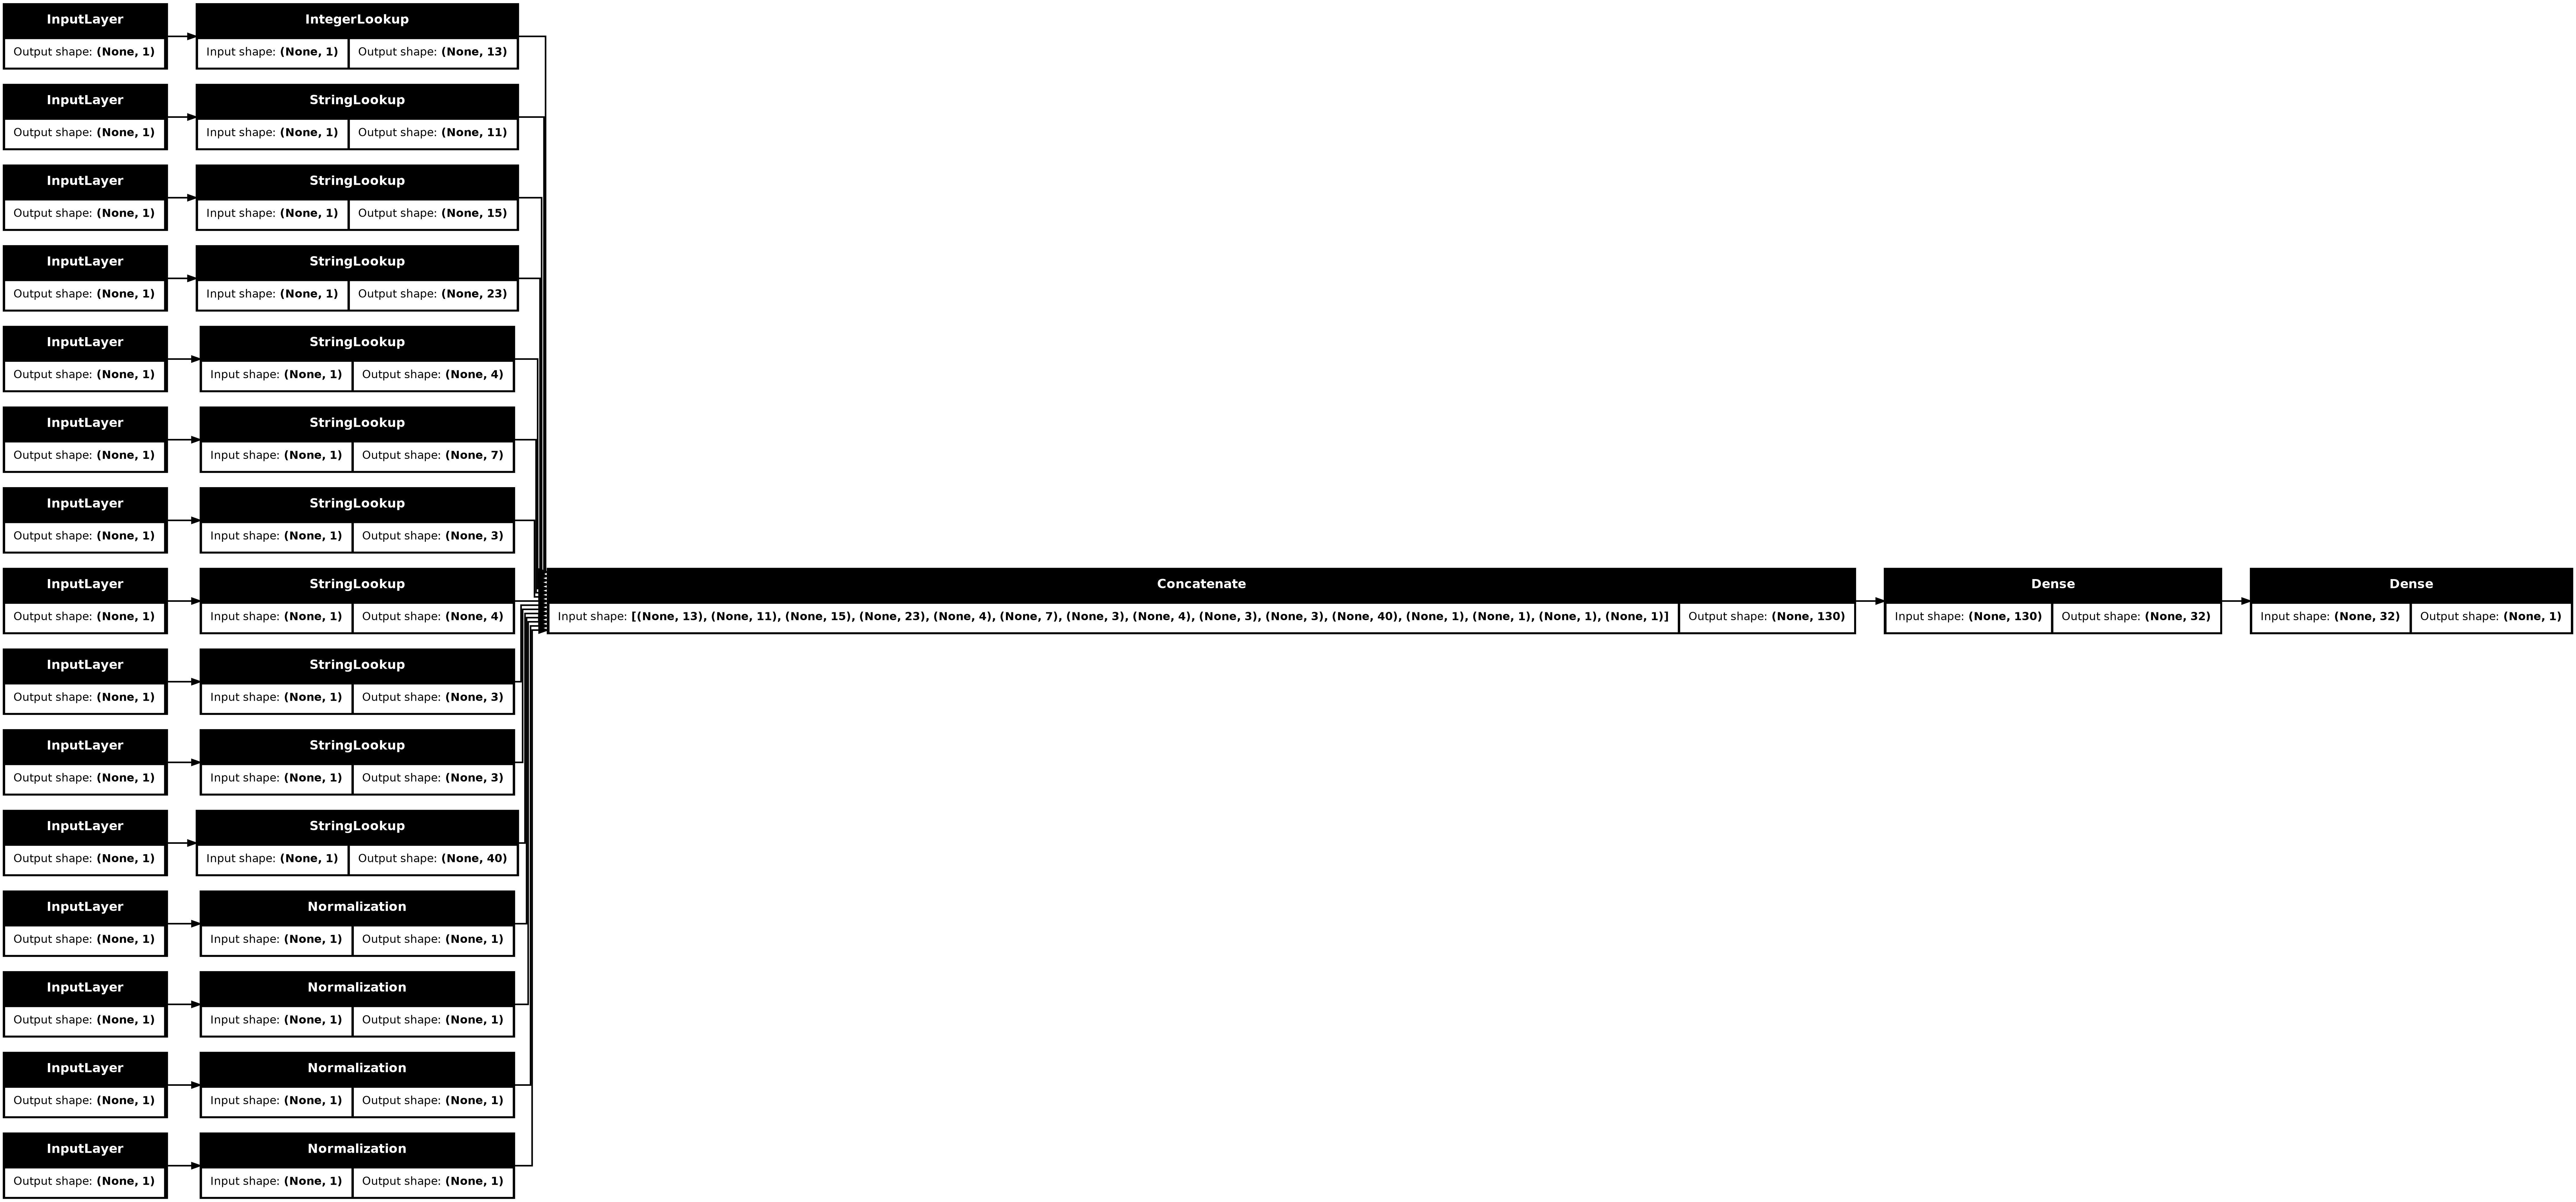

In [46]:
keras.utils.plot_model(model, show_shapes=True, rankdir="LR")

Aseguramos que Keras use TensorFlow como backend, para asegurar que el modelo pueda usar strings como entradas

In [47]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

Entrenamos el modelo con los datos en el formato tf.Dataset

In [48]:
%%time
history = model.fit(train_ds, epochs=50, validation_data=val_ds)

Epoch 1/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8747 - loss: 0.2775 - recall: 0.1158 - val_accuracy: 0.8753 - val_loss: 0.2499 - val_recall: 0.2610
Epoch 2/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8912 - loss: 0.2328 - recall: 0.2997 - val_accuracy: 0.8909 - val_loss: 0.2316 - val_recall: 0.3171
Epoch 3/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9059 - loss: 0.2176 - recall: 0.4126 - val_accuracy: 0.9057 - val_loss: 0.2198 - val_recall: 0.4799
Epoch 4/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9095 - loss: 0.2086 - recall: 0.4653 - val_accuracy: 0.9057 - val_loss: 0.2160 - val_recall: 0.4022
Epoch 5/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9129 - loss: 0.2028 - recall: 0.4812 - val_accuracy: 0.9085 - val_loss: 0.2113 - val_recall: 0.5388
Epoch 6/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9130 - loss: 0.1992 - recall: 0.4946 - val_accuracy: 0.9091 - val_loss: 0.2076 - val_recall:

In [49]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch

In [50]:
hist.head()

,accuracy,loss,recall,val_accuracy,val_loss,val_recall,epoch
0,0.874721,0.277530,0.115779,0.875312,0.249913,0.260992,0
1,0.891229,0.232782,0.299707,0.890898,0.231608,0.317119,1
2,0.905922,0.217554,0.412555,0.905651,0.219776,0.479888,2
3,0.909521,0.208551,0.465315,0.905651,0.215952,0.402245,3
4,0.912941,0.202820,0.481192,0.908507,0.211280,0.538821,4


In [51]:
import matplotlib.pyplot as plt

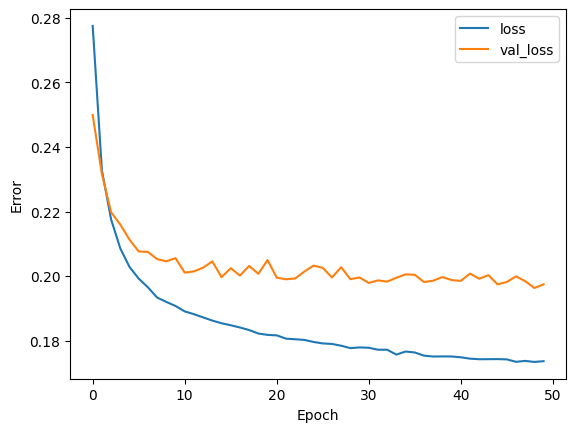

In [52]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.legend()

In [53]:
test_res = {}
test_res['dnn_model'] = model.evaluate(test_ds, verbose=0)

In [54]:
test_res

{'dnn_model': [0.18725444376468658, 0.926803708076477, 0.5778656005859375]}